In [1]:
import os
import matplotlib.pyplot as plt

DATASET = "quandang/vietnamese-foods"
DATASET_VERSION = "11"   # cố định version; dùng lại khi ghi split_v2.json

# Gốc repo: nếu notebook nằm trong notebooks/ thì repo ở thư mục cha
ROOT = ".." if (os.path.isdir("../data") or os.path.isdir("../results")) else "."

# Chọn đường dẫn dữ liệu: máy cá nhân dùng data/30VNFoods, Colab tải từ Kaggle
LOCAL_DATA = os.path.join(ROOT, "data", "30VNFoods")
if os.path.isdir(LOCAL_DATA):
    path = LOCAL_DATA
else:
    import kagglehub
    path = kagglehub.dataset_download(f"{DATASET}/versions/{DATASET_VERSION}")
print("Dataset path:", path)

# Thư mục ghi kết quả (giống cấu trúc A1)
FIG_DIR = os.path.join(ROOT, "results", "a2", "figures")
TABLE_DIR = os.path.join(ROOT, "results", "a2", "tables")
SPLIT_DIR = os.path.join(ROOT, "results", "a2", "splits")
for d in [FIG_DIR, TABLE_DIR, SPLIT_DIR]:
    os.makedirs(d, exist_ok=True)

# Hình hiển thị trong notebook lưu dạng JPEG, độ phân giải thấp → notebook nhẹ
# (file PNG cho report vẫn lưu riêng bằng savefig với dpi=150)
%config InlineBackend.figure_format = "jpeg"
plt.rcParams["figure.dpi"] = 72


Dataset path: ..\data\30VNFoods


In [2]:
import os

print(sorted(os.listdir(path)))

['.complete', 'Images', 'LICENSE', 'Urls']


In [3]:
license_path = os.path.join(path, "LICENSE")
if os.path.exists(license_path):
    print(open(license_path).read()[:500])
else:
    print("Không có file LICENSE trong", path)


MIT License

Copyright (c) 2021 Quan Dang

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright not


In [4]:
images_dir = os.path.join(path, "Images")
if not os.path.isdir(images_dir):
    images_dir = path
print(sorted(os.listdir(images_dir)))


['Test', 'Train', 'Validate']


In [5]:
train_dir = os.path.join(images_dir, "Train")
train_classes = sorted(os.listdir(train_dir))

print("Số lớp:", len(train_classes))
print(train_classes)

Số lớp: 30
['Banh beo', 'Banh bot loc', 'Banh can', 'Banh canh', 'Banh chung', 'Banh cuon', 'Banh duc', 'Banh gio', 'Banh khot', 'Banh mi', 'Banh pia', 'Banh tet', 'Banh trang nuong', 'Banh xeo', 'Bun bo Hue', 'Bun dau mam tom', 'Bun mam', 'Bun rieu', 'Bun thit nuong', 'Ca kho to', 'Canh chua', 'Cao lau', 'Chao long', 'Com tam', 'Goi cuon', 'Hu tieu', 'Mi quang', 'Nem chua', 'Pho', 'Xoi xeo']


In [6]:
val_classes = sorted(os.listdir(os.path.join(images_dir, "Validate")))
test_classes = sorted(os.listdir(os.path.join(images_dir, "Test")))

print("Val giống Train?", val_classes == train_classes)
print("Test giống Train?", test_classes == train_classes)

Val giống Train? True
Test giống Train? True


In [7]:
import pandas as pd

rows = []
for split in ["Train", "Validate", "Test"]:
    for cls in train_classes:
        cls_dir = os.path.join(images_dir, split, cls)
        n = len(os.listdir(cls_dir))
        rows.append({"split": split, "class": cls, "count": n})

df_counts = pd.DataFrame(rows)
df_counts.head()

,split,class,count
0,Train,Banh beo,451
1,Train,Banh bot loc,503
2,Train,Banh can,520
3,Train,Banh canh,674
4,Train,Banh chung,354


In [8]:
table = df_counts.pivot(index="class", columns="split", values="count")
table["Total"] = table.sum(axis=1)
table = table.sort_values("Total", ascending=False)
table

split,Test,Train,Validate,Total
class,,,,
Bun bo Hue,306,1071,153,1530
Banh mi,268,935,133,1336
Banh xeo,235,821,117,1173
Bun rieu,231,805,115,1151
Banh cuon,228,798,114,1140
Chao long,215,751,107,1073
Hu tieu,197,688,98,983
Banh canh,193,674,97,964
Com tam,189,659,94,942


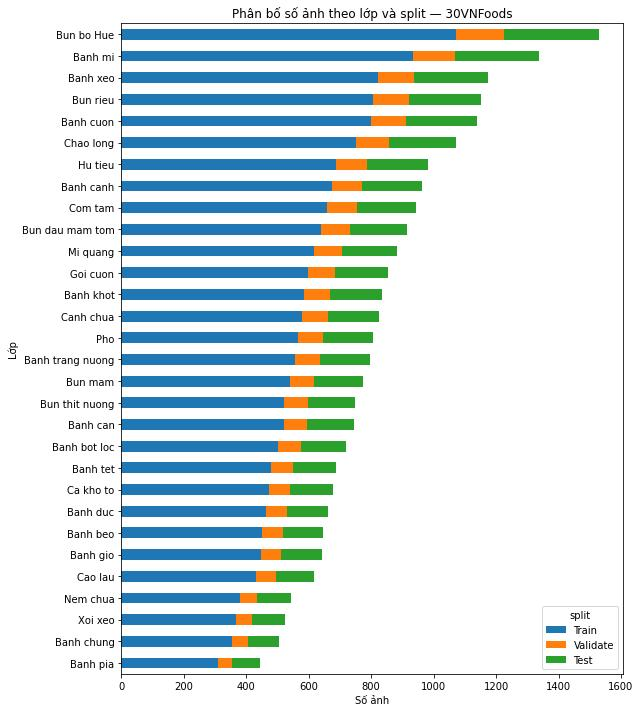

In [9]:
import matplotlib.pyplot as plt

plot_table = table[["Train", "Validate", "Test"]].sort_values("Train")

plot_table.plot(kind="barh", stacked=True, figsize=(9, 10))
plt.xlabel("Số ảnh")
plt.ylabel("Lớp")
plt.title("Phân bố số ảnh theo lớp và split — 30VNFoods")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "a2_class_distribution.png"), dpi=150)
plt.show()

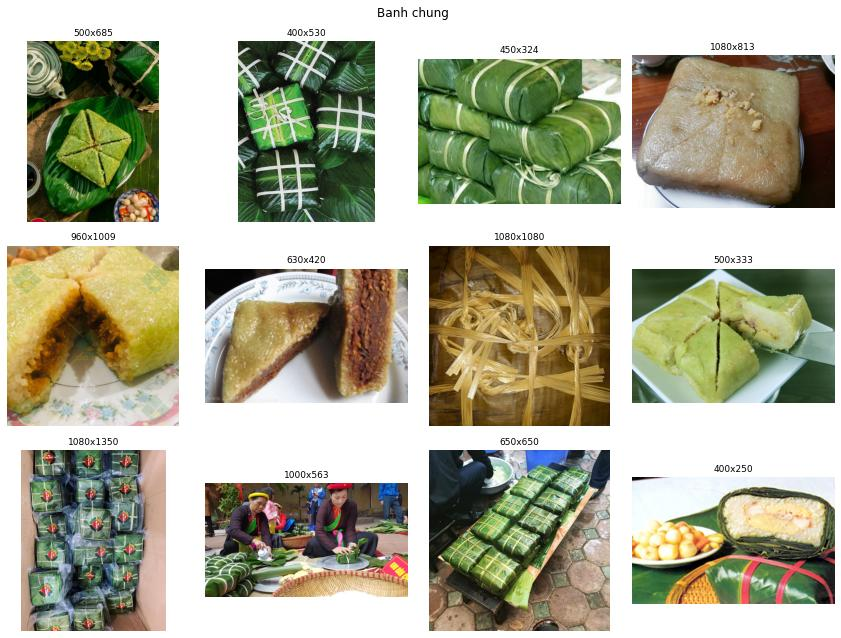

In [10]:
import random
from PIL import Image

random.seed(42)

cls = "Banh chung"   # đổi tên lớp ở đây để xem lớp khác
cls_dir = os.path.join(train_dir, cls)
files = random.sample(sorted(os.listdir(cls_dir)), 12)

plt.figure(figsize=(12, 9))
for i, f in enumerate(files):
    img = Image.open(os.path.join(cls_dir, f))
    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(f"{img.size[0]}x{img.size[1]}", fontsize=9)
    plt.axis("off")
plt.suptitle(cls)
plt.tight_layout()
plt.show()

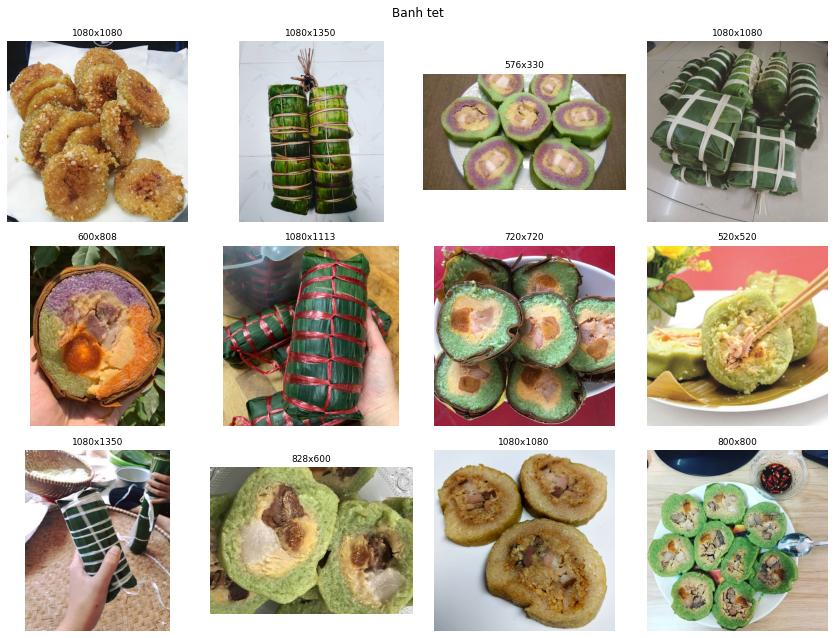

In [11]:
import random
from PIL import Image

random.seed(42)

cls = "Banh tet"   # đổi tên lớp ở đây để xem lớp khác
cls_dir = os.path.join(train_dir, cls)
files = random.sample(sorted(os.listdir(cls_dir)), 12)

plt.figure(figsize=(12, 9))
for i, f in enumerate(files):
    img = Image.open(os.path.join(cls_dir, f))
    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(f"{img.size[0]}x{img.size[1]}", fontsize=9)
    plt.axis("off")
plt.suptitle(cls)
plt.tight_layout()
plt.show()

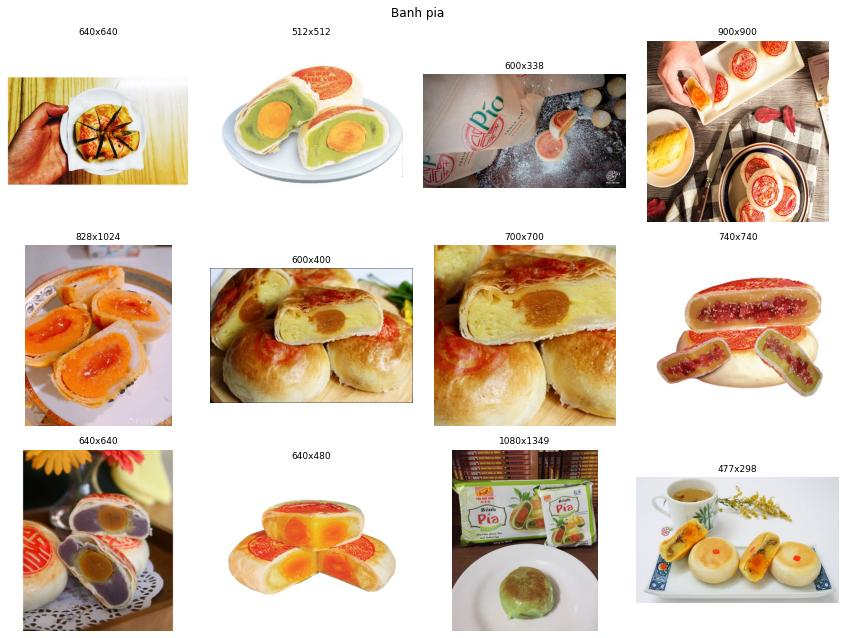

In [12]:
import random
from PIL import Image

random.seed(42)

cls = "Banh pia"   # đổi tên lớp ở đây để xem lớp khác
cls_dir = os.path.join(train_dir, cls)
files = random.sample(sorted(os.listdir(cls_dir)), 12)

plt.figure(figsize=(12, 9))
for i, f in enumerate(files):
    img = Image.open(os.path.join(cls_dir, f))
    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(f"{img.size[0]}x{img.size[1]}", fontsize=9)
    plt.axis("off")
plt.suptitle(cls)
plt.tight_layout()
plt.show()

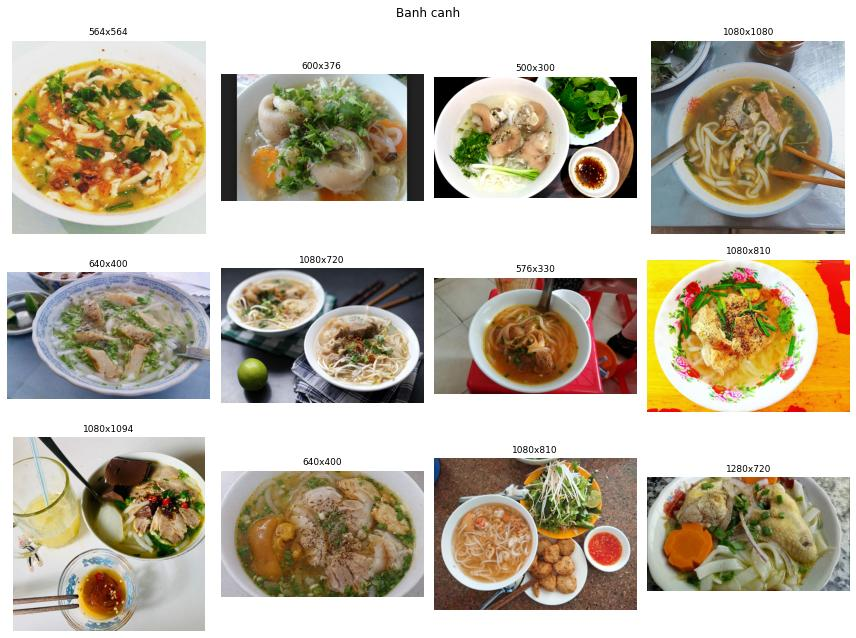

In [13]:
import random
from PIL import Image

random.seed(42)

cls = "Banh canh"   # đổi tên lớp ở đây để xem lớp khác
cls_dir = os.path.join(train_dir, cls)
files = random.sample(sorted(os.listdir(cls_dir)), 12)

plt.figure(figsize=(12, 9))
for i, f in enumerate(files):
    img = Image.open(os.path.join(cls_dir, f))
    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(f"{img.size[0]}x{img.size[1]}", fontsize=9)
    plt.axis("off")
plt.suptitle(cls)
plt.tight_layout()
plt.show()

**Nhận xét (Banh canh vs Bun bo Hue):** Banh canh đa dạng nội lớp (nước trong / cam / cam đỏ, nhiều kiểu topping). Trên mẫu 12 ảnh, sợi lộ rõ ở 8/12 ảnh Banh canh nhưng chỉ 3/12 ảnh Bun bo Hue (topping che sợi).
→ **H2:** nhầm lẫn Banh canh ↔ Bun bo Hue / Bun rieu tập trung ở ảnh Banh canh nước cam đỏ không thấy sợi, lệch về phía Bun bo Hue (lớp đông nhất).

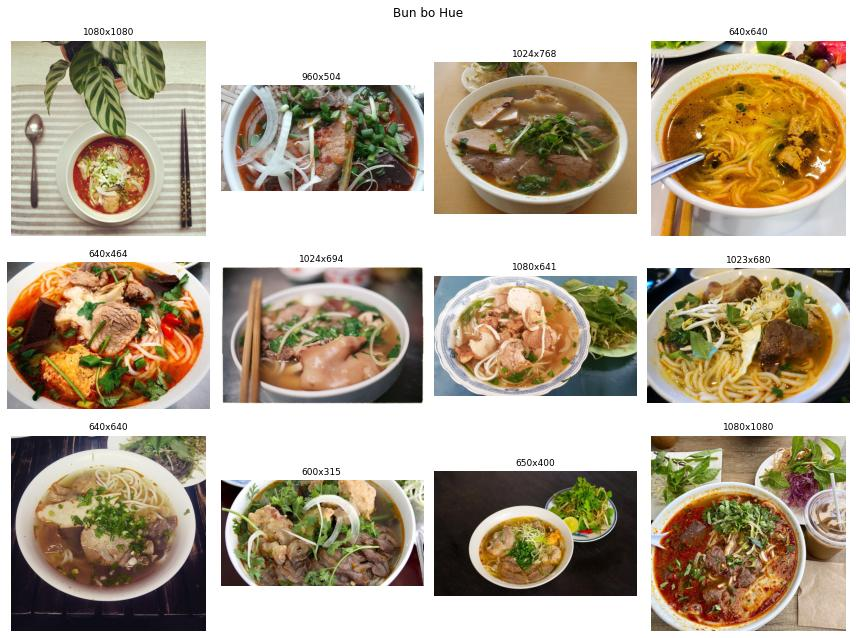

In [14]:
import random
from PIL import Image

random.seed(42)

cls = "Bun bo Hue"   # đổi tên lớp ở đây để xem lớp khác
cls_dir = os.path.join(train_dir, cls)
files = random.sample(sorted(os.listdir(cls_dir)), 12)

plt.figure(figsize=(12, 9))
for i, f in enumerate(files):
    img = Image.open(os.path.join(cls_dir, f))
    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(f"{img.size[0]}x{img.size[1]}", fontsize=9)
    plt.axis("off")
plt.suptitle(cls)
plt.tight_layout()
plt.show()

In [15]:
from tqdm import tqdm

rows = []
for cls in tqdm(train_classes):
    cls_dir = os.path.join(train_dir, cls)
    for f in sorted(os.listdir(cls_dir)):
        fpath = os.path.join(cls_dir, f)
        try:
            img = Image.open(fpath)
            w, h = img.size
            rows.append({"class": cls, "file": f, "width": w, "height": h, "mode": img.mode})
        except Exception as e:
            rows.append({"class": cls, "file": f, "width": None, "height": None, "mode": "ERROR"})

df_size = pd.DataFrame(rows)
print("Số ảnh đã đọc:", len(df_size))
print("Số file lỗi:", (df_size["mode"] == "ERROR").sum())

100%|██████████| 30/30 [01:58<00:00,  3.94s/it]

Số ảnh đã đọc: 17581
Số file lỗi: 0


In [16]:
rows_vt = []
for split in ["Validate", "Test"]:
    for cls in train_classes:
        cls_dir = os.path.join(images_dir, split, cls)
        for f in sorted(os.listdir(cls_dir)):
            try:
                img = Image.open(os.path.join(cls_dir, f))
                rows_vt.append({"split": split, "mode": img.mode})
            except Exception:
                rows_vt.append({"split": split, "mode": "ERROR"})

print(pd.DataFrame(rows_vt).groupby(["split", "mode"]).size())

split     mode
Test      RGB     5040
Validate  RGB     2515
dtype: int64


In [17]:
df_size["ratio"] = df_size["width"] / df_size["height"]

print(df_size[["width", "height", "ratio"]].describe())
print()
print(df_size["mode"].value_counts())

              width        height         ratio
count  17581.000000  17581.000000  17581.000000
mean     903.050850    779.755418      1.261200
std      419.047202    412.371059      0.343852
min      100.000000     83.000000      0.400000
25%      640.000000    440.000000      1.000000
50%     1000.000000    720.000000      1.333333
75%     1080.000000   1080.000000      1.501155
max     7360.000000   5184.000000      3.900000

mode
RGB    17581
Name: count, dtype: int64


In [18]:
df_size["short_side"] = df_size[["width", "height"]].min(axis=1)

n = len(df_size)
small = (df_size["short_side"] < 224).sum()
extreme = ((df_size["ratio"] > 2) | (df_size["ratio"] < 0.5)).sum()
square = (df_size["ratio"] == 1).sum()

print(f"Cạnh ngắn < 224px:      {small} ảnh ({small/n:.1%})")
print(f"Tỷ lệ cực (>2 hoặc <0.5): {extreme} ảnh ({extreme/n:.1%})")
print(f"Ảnh vuông đúng 1:1:     {square} ảnh ({square/n:.1%})")

Cạnh ngắn < 224px:      251 ảnh (1.4%)
Tỷ lệ cực (>2 hoặc <0.5): 193 ảnh (1.1%)
Ảnh vuông đúng 1:1:     4327 ảnh (24.6%)


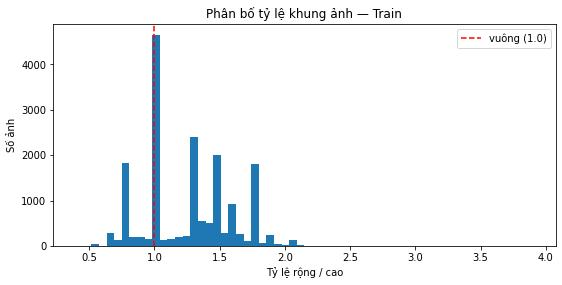

In [19]:
plt.figure(figsize=(9, 4))
plt.hist(df_size["ratio"], bins=60)
plt.axvline(1.0, color="red", linestyle="--", label="vuông (1.0)")
plt.xlabel("Tỷ lệ rộng / cao")
plt.ylabel("Số ảnh")
plt.title("Phân bố tỷ lệ khung ảnh — Train")
plt.legend()
plt.savefig(os.path.join(FIG_DIR, "a2_aspect_ratio.png"), dpi=150)
plt.show()

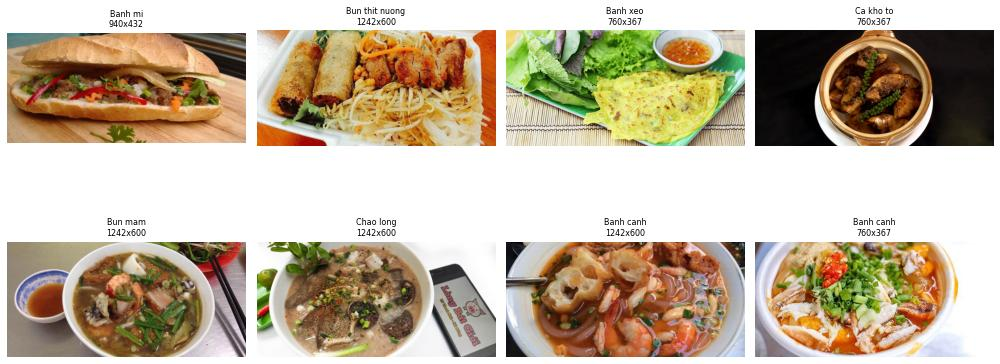

In [20]:
extreme_df = df_size[(df_size["ratio"] > 2) | (df_size["ratio"] < 0.5)].sample(8, random_state=42)

plt.figure(figsize=(14, 7))
for i, (_, row) in enumerate(extreme_df.iterrows()):
    img = Image.open(os.path.join(train_dir, row["class"], row["file"]))
    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title(f"{row['class']}\n{row['width']}x{row['height']}", fontsize=8)
    plt.axis("off")
plt.tight_layout()
plt.show()

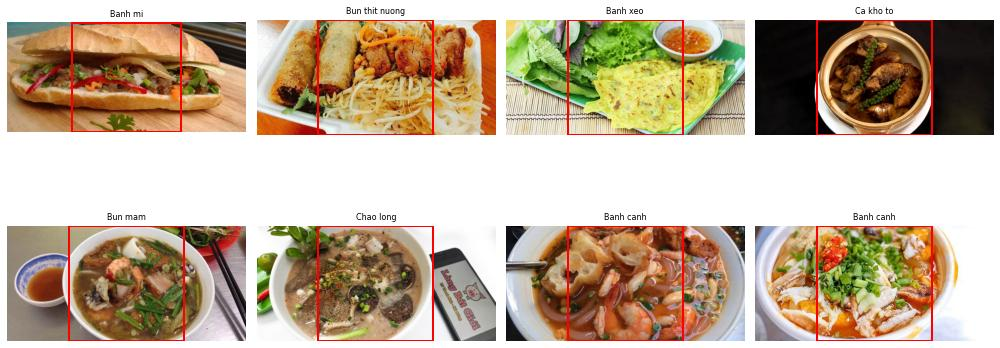

In [21]:
import matplotlib.patches as patches

plt.figure(figsize=(14, 7))
for i, (_, row) in enumerate(extreme_df.iterrows()):
    img = Image.open(os.path.join(train_dir, row["class"], row["file"]))
    w, h = img.size
    side = min(w, h)
    left = (w - side) / 2
    top = (h - side) / 2

    ax = plt.subplot(2, 4, i + 1)
    ax.imshow(img)
    ax.add_patch(patches.Rectangle((left, top), side, side,
                                   fill=False, edgecolor="red", linewidth=2))
    ax.set_title(row["class"], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [22]:
small_df = df_size[df_size["short_side"] < 224]

small_by_class = small_df["class"].value_counts()
total_by_class = df_size["class"].value_counts()
small_pct = (small_by_class / total_by_class * 100).fillna(0).sort_values(ascending=False)

print(small_pct.head(10).round(1))


class
Canh chua           2.8
Banh tet            2.7
Banh trang nuong    2.7
Banh duc            2.4
Nem chua            2.4
Xoi xeo             2.2
Banh beo            2.0
Banh bot loc        2.0
Banh canh           1.9
Banh can            1.9
Name: count, dtype: float64


In [23]:
import numpy as np

sample_df = df_size.sample(3000, random_state=42)

pixel_sum = np.zeros(3)
pixel_sq_sum = np.zeros(3)
n_pixels = 0
img_rows = []

for _, row in tqdm(sample_df.iterrows(), total=len(sample_df)):
    img = Image.open(os.path.join(train_dir, row["class"], row["file"])).convert("RGB")
    img = img.resize((64, 64))
    arr = np.asarray(img, dtype=np.float64) / 255.0

    pixels = arr.reshape(-1, 3)
    pixel_sum += pixels.sum(axis=0)
    pixel_sq_sum += (pixels ** 2).sum(axis=0)
    n_pixels += pixels.shape[0]

    img_rows.append({"class": row["class"], "brightness": arr.mean()})

mean = pixel_sum / n_pixels
std = np.sqrt(pixel_sq_sum / n_pixels - mean ** 2)

print("Mean (R, G, B):", mean.round(3))
print("Std  (R, G, B):", std.round(3))
print("ImageNet mean: [0.485 0.456 0.406]")
print("ImageNet std:  [0.229 0.224 0.225]")

100%|██████████| 3000/3000 [00:34<00:00, 87.51it/s] 

Mean (R, G, B): [0.578 0.512 0.399]
Std  (R, G, B): [0.26  0.255 0.282]
ImageNet mean: [0.485 0.456 0.406]
ImageNet std:  [0.229 0.224 0.225]


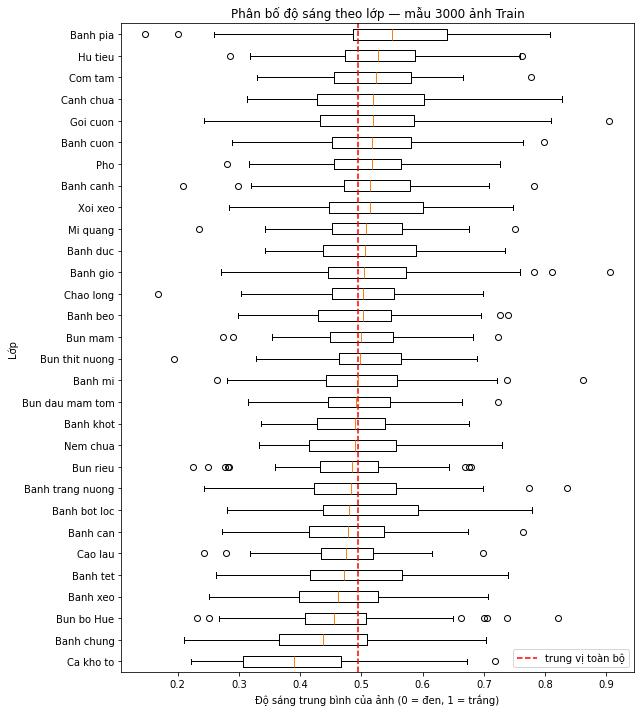

In [24]:
df_bright = pd.DataFrame(img_rows)
order = df_bright.groupby("class")["brightness"].median().sort_values().index
data = [df_bright.loc[df_bright["class"] == c, "brightness"] for c in order]

plt.figure(figsize=(9, 10))
plt.boxplot(data, vert=False)
plt.yticks(range(1, len(order) + 1), order)
plt.axvline(df_bright["brightness"].median(), color="red", linestyle="--", label="trung vị toàn bộ")
plt.xlabel("Độ sáng trung bình của ảnh (0 = đen, 1 = trắng)")
plt.ylabel("Lớp")
plt.title("Phân bố độ sáng theo lớp — mẫu 3000 ảnh Train")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "a2_brightness_by_class.png"), dpi=150)
plt.show()


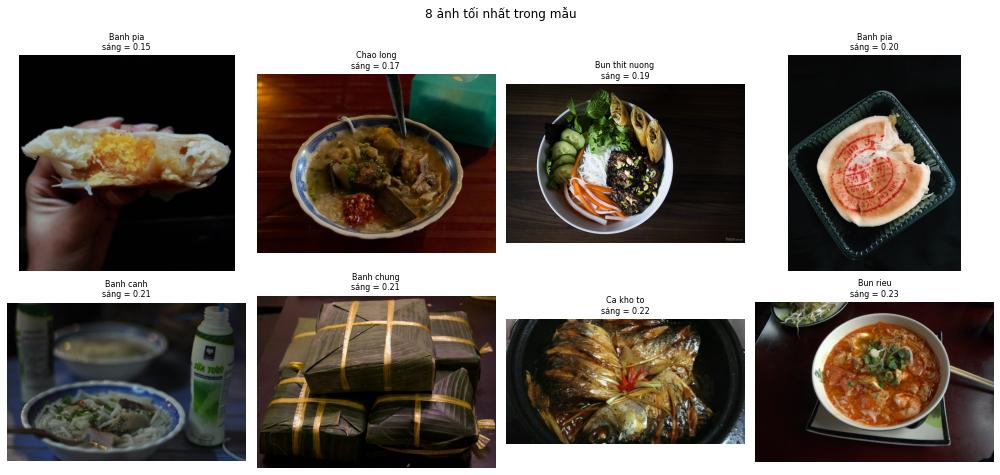

In [25]:
df_bright["file"] = sample_df["file"].values

darkest = df_bright.sort_values("brightness").head(8)

plt.figure(figsize=(14, 7))
for i, (_, row) in enumerate(darkest.iterrows()):
    img = Image.open(os.path.join(train_dir, row["class"], row["file"]))
    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title(f"{row['class']}\nsáng = {row['brightness']:.2f}", fontsize=8)
    plt.axis("off")
plt.suptitle("8 ảnh tối nhất trong mẫu")
plt.tight_layout()
plt.show()

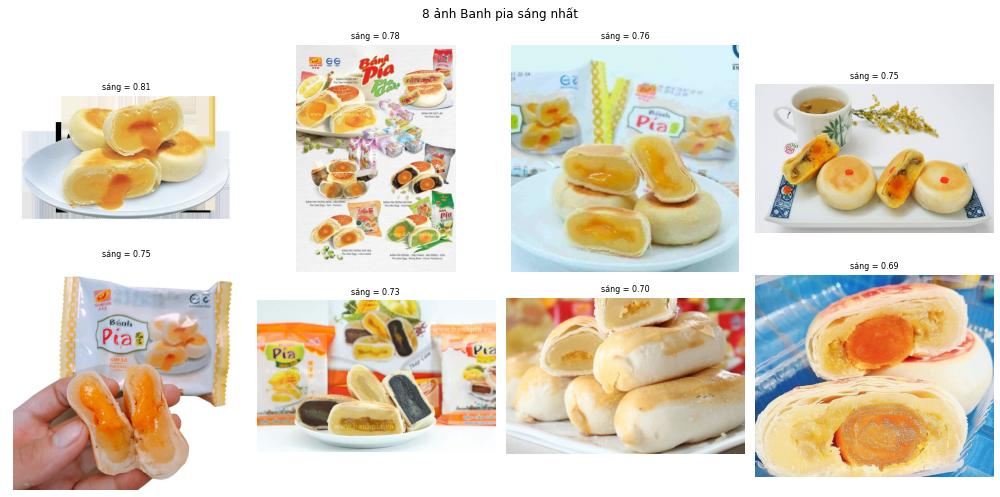

In [26]:
pia_bright = df_bright[df_bright["class"] == "Banh pia"].sort_values("brightness", ascending=False).head(8)

plt.figure(figsize=(14, 7))
for i, (_, row) in enumerate(pia_bright.iterrows()):
    img = Image.open(os.path.join(train_dir, row["class"], row["file"]))
    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title(f"sáng = {row['brightness']:.2f}", fontsize=8)
    plt.axis("off")
plt.suptitle("8 ảnh Banh pia sáng nhất")
plt.tight_layout()
plt.show()

In [27]:
import hashlib

rows = []
for split in ["Train", "Validate", "Test"]:
    for cls in tqdm(train_classes, desc=split):
        cls_dir = os.path.join(images_dir, split, cls)
        for f in sorted(os.listdir(cls_dir)):
            with open(os.path.join(cls_dir, f), "rb") as fh:
                md5 = hashlib.md5(fh.read()).hexdigest()
            rows.append({"split": split, "class": cls, "file": f, "md5": md5})

df_all = pd.DataFrame(rows)
print("Tổng số ảnh:", len(df_all))
print("Số MD5 khác nhau:", df_all["md5"].nunique())

Test: 100%|██████████| 30/30 [00:03<00:00,  9.01it/s]

Tổng số ảnh: 25136
Số MD5 khác nhau: 25070


In [28]:
dup = df_all[df_all.duplicated("md5", keep=False)]
print("Số ảnh nằm trong nhóm trùng:", len(dup))

groups = dup.groupby("md5").agg(
    n_files=("file", "size"),
    n_splits=("split", "nunique"),
    n_classes=("class", "nunique"),
)
print("Số nhóm trùng:", len(groups))
print("Nhóm trùng xuyên split (leakage):", (groups["n_splits"] > 1).sum())
print("Nhóm trùng khác nhãn:", (groups["n_classes"] > 1).sum())

Số ảnh nằm trong nhóm trùng: 129
Số nhóm trùng: 63
Nhóm trùng xuyên split (leakage): 40
Nhóm trùng khác nhãn: 38


In [29]:
conflict_md5 = groups[groups["n_classes"] > 1].index
conflict = dup[dup["md5"].isin(conflict_md5)]

pairs = conflict.groupby("md5")["class"].apply(lambda s: " / ".join(sorted(set(s))))
print(pairs.value_counts())

class
Bun bo Hue / Bun rieu                 4
Banh duc / Banh gio                   3
Banh chung / Banh tet                 3
Banh can / Banh khot                  3
Banh canh / Hu tieu                   2
Banh beo / Banh bot loc               2
Cao lau / Mi quang                    2
Banh cuon / Banh duc                  2
Banh bot loc / Banh khot              1
Banh canh / Bun rieu / Hu tieu        1
Banh cuon / Nem chua                  1
Banh cuon / Banh gio                  1
Banh mi / Goi cuon                    1
Banh beo / Banh bot loc / Banh duc    1
Banh canh / Bun rieu                  1
Banh xeo / Bun bo Hue / Bun rieu      1
Bun bo Hue / Pho                      1
Ca kho to / Canh chua                 1
Bun bo Hue / Mi quang                 1
Hu tieu / Mi quang                    1
Banh bot loc / Goi cuon               1
Banh beo / Banh gio                   1
Banh bot loc / Banh gio               1
Banh cuon / Bun bo Hue                1
Chao long / Hu tieu               

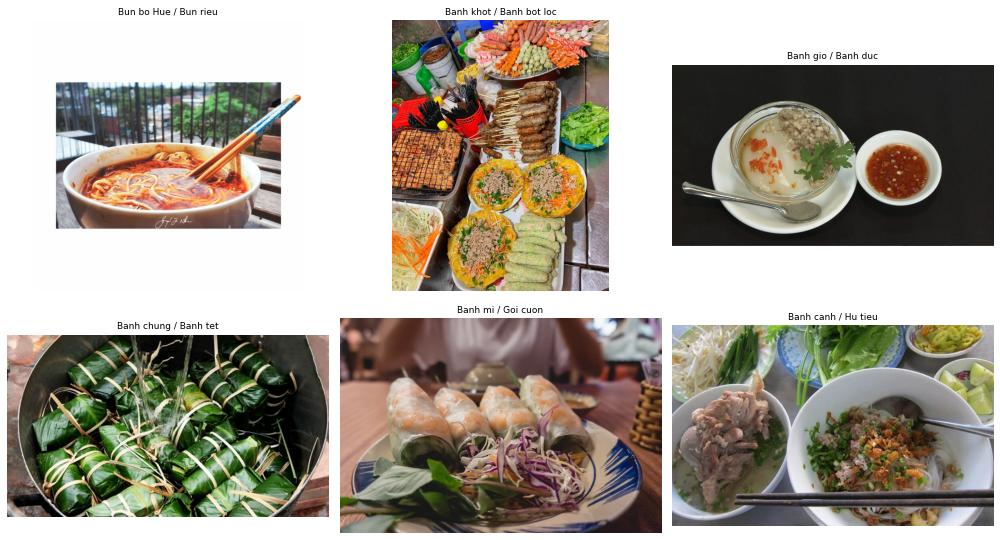

In [30]:
show_md5 = conflict_md5[:6]

plt.figure(figsize=(14, 8))
for i, m in enumerate(show_md5):
    row = conflict[conflict["md5"] == m].iloc[0]
    labels = conflict[conflict["md5"] == m]["class"].unique()
    img = Image.open(os.path.join(images_dir, row["split"], row["class"], row["file"]))
    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(" / ".join(labels), fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

### Split v1 (chỉ MD5) — đã bị thay bằng v2

Giữ lại để so sánh: MD5 chỉ bắt được bản sao giống từng byte. Không ghi file v1 nữa; split chính thức là `split_v2.json` (pHash, phía dưới).

In [31]:
# 1. MD5 mang nhiều hơn 1 nhãn → mâu thuẫn
n_cls = df_all.groupby("md5")["class"].nunique()
conflict_set = set(n_cls[n_cls > 1].index)

# 2. MD5 có mặt ở Validate / Test
val_set = set(df_all[df_all["split"] == "Validate"]["md5"])
test_set = set(df_all[df_all["split"] == "Test"]["md5"])

df_all["conflict"] = df_all["md5"].isin(conflict_set)
df_all["leak"] = (
    ((df_all["split"] == "Train") & df_all["md5"].isin(val_set | test_set)) |
    ((df_all["split"] == "Validate") & df_all["md5"].isin(test_set))
)

# 3. Áp quy tắc
df_clean = df_all[~df_all["conflict"] & ~df_all["leak"]]
df_clean = df_clean.drop_duplicates(subset=["split", "md5"])

before = df_all["split"].value_counts()
after = df_clean["split"].value_counts()
print(pd.DataFrame({"trước": before, "sau": after, "bỏ": before - after}))

          trước    sau  bỏ
split                     
Train     17581  17515  66
Test       5040   5014  26
Validate   2515   2503  12


In [32]:
removed = df_all.groupby("class").size() - df_clean.groupby("class").size()
print(removed.sort_values(ascending=False).head(8))

class
Mi quang        10
Bun bo Hue       8
Bun rieu         7
Hu tieu          7
Banh can         7
Banh bot loc     6
Banh canh        6
Banh duc         6
dtype: int64


In [33]:
import imagehash

hashes = []
for _, row in tqdm(df_all.iterrows(), total=len(df_all)):
    img = Image.open(os.path.join(images_dir, row["split"], row["class"], row["file"]))
    img.draft("L", (128, 128))
    h = imagehash.phash(img.convert("L"))
    hashes.append(np.packbits(h.hash.flatten()))

H = np.stack(hashes)
print(H.shape)

100%|██████████| 25136/25136 [02:36<00:00, 161.02it/s]

(25136, 8)


In [34]:
popcount = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)

N = len(H)
pairs = []
chunk = 200
for start in tqdm(range(0, N, chunk)):
    block = H[start:start + chunk]
    xor = np.bitwise_xor(block[:, None, :], H[None, :, :])
    dist = popcount[xor].sum(axis=2)
    ii, jj = np.nonzero(dist <= 8)
    ii = ii + start
    keep = jj > ii
    for i, j in zip(ii[keep], jj[keep]):
        pairs.append((i, j, dist[i - start, j]))

df_pairs = pd.DataFrame(pairs, columns=["i", "j", "dist"])
print("Số cặp có khoảng cách ≤ 8:", len(df_pairs))

100%|██████████| 126/126 [00:28<00:00,  4.48it/s]

Số cặp có khoảng cách ≤ 8: 490


In [35]:
split = df_all["split"].values
label = df_all["class"].values
df_pairs["cross_split"] = split[df_pairs["i"]] != split[df_pairs["j"]]
df_pairs["cross_class"] = label[df_pairs["i"]] != label[df_pairs["j"]]

summary = df_pairs.groupby("dist").agg(
    n_pairs=("i", "size"),
    cross_split=("cross_split", "sum"),
    cross_class=("cross_class", "sum"),
)
print(summary)

      n_pairs  cross_split  cross_class
dist                                   
0         227          121           60
2          56           28            2
4          52           22            2
6          69           32            1
8          86           47           18


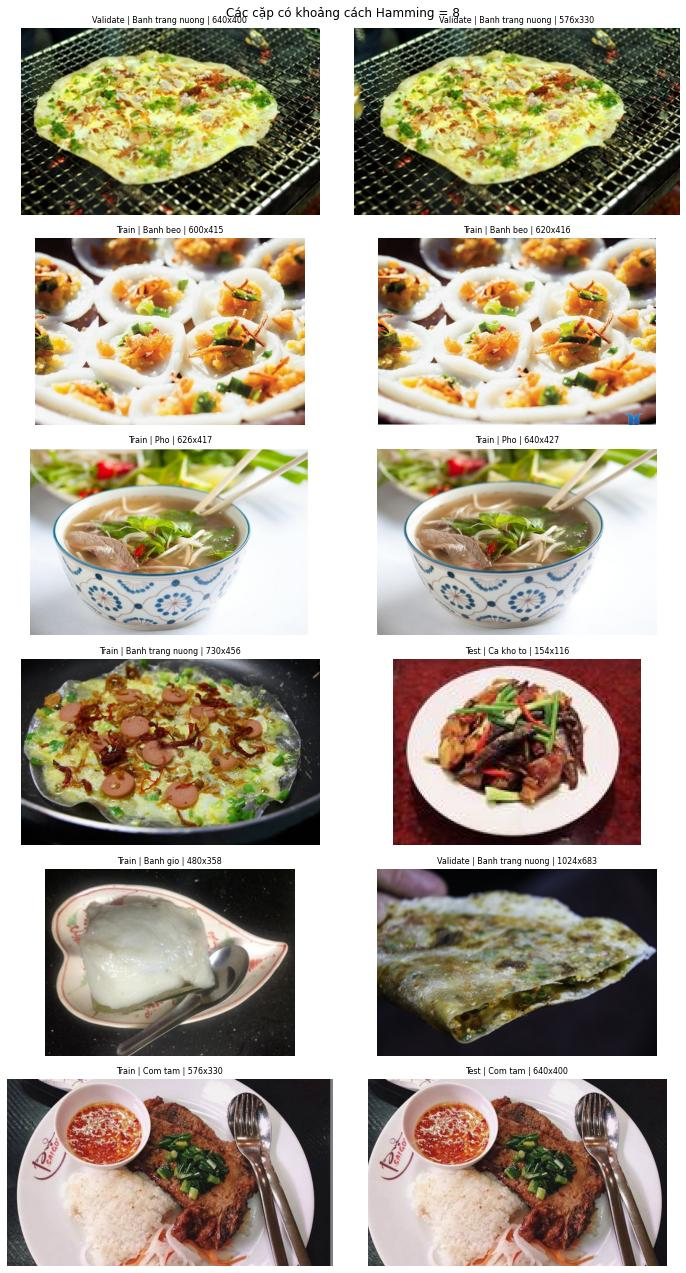

In [36]:
d = 8   # thử lần lượt 2, 4, 6, 8

subset = df_pairs[df_pairs["dist"] == d]
sample = subset.sample(min(6, len(subset)), random_state=42)

plt.figure(figsize=(10, 18))
for k, (_, p) in enumerate(sample.iterrows()):
    for col, idx in enumerate([p["i"], p["j"]]):
        r = df_all.iloc[int(idx)]
        img = Image.open(os.path.join(images_dir, r["split"], r["class"], r["file"]))
        plt.subplot(6, 2, 2 * k + col + 1)
        plt.imshow(img)
        plt.title(f"{r['split']} | {r['class']} | {img.size[0]}x{img.size[1]}", fontsize=8)
        plt.axis("off")
plt.suptitle(f"Các cặp có khoảng cách Hamming = {d}")
plt.tight_layout()
plt.show()

In [37]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

same_class = ~df_pairs["cross_class"]
edges = df_pairs[(df_pairs["dist"] <= 6) | ((df_pairs["dist"] == 8) & same_class)]

N = len(df_all)
graph = coo_matrix((np.ones(len(edges)), (edges["i"], edges["j"])), shape=(N, N))
n_comp, comp = connected_components(graph, directed=False)
df_all["cluster"] = comp

cl_size = df_all.groupby("cluster")["file"].transform("size")
cl_ncls = df_all.groupby("cluster")["class"].transform("nunique")
cl_nsplit = df_all.groupby("cluster")["split"].transform("nunique")

print("Số cụm có ≥ 2 ảnh:", df_all.loc[cl_size > 1, "cluster"].nunique())
print("Cụm trải nhiều split (leakage):", df_all.loc[cl_nsplit > 1, "cluster"].nunique())
print("Cụm mâu thuẫn nhãn:", df_all.loc[cl_ncls > 1, "cluster"].nunique())

Số cụm có ≥ 2 ảnh: 427
Cụm trải nhiều split (leakage): 222
Cụm mâu thuẫn nhãn: 56


In [38]:
cl_sizes = df_all.groupby("cluster").size().sort_values(ascending=False)
print(cl_sizes.head(10))

cluster
6488     3
2575     3
5272     3
13046    3
5103     3
4879     3
1642     3
8612     3
852      3
1547     3
dtype: int64


In [39]:
priority = {"Test": 0, "Validate": 1, "Train": 2}
df_all["prio"] = df_all["split"].map(priority)

df_v2 = df_all[cl_ncls == 1]
df_v2 = df_v2.sort_values(["cluster", "prio", "file"])
df_v2 = df_v2.drop_duplicates(subset="cluster", keep="first")

before = df_all["split"].value_counts()
after = df_v2["split"].value_counts()
print(pd.DataFrame({"trước": before, "sau": after, "bỏ": before - after}))

          trước    sau   bỏ
split                      
Train     17581  17164  417
Test       5040   4984   56
Validate   2515   2481   34


In [40]:
orig = df_all.groupby("class").size()
kept = df_v2.groupby("class").size()
loss_pct = ((orig - kept) / orig * 100).sort_values(ascending=False)

print("Lớp mất nhiều nhất (%):")
print(loss_pct.head(8).round(1))
print()
print("5 lớp ít ảnh Train nhất:")
print(df_v2[df_v2["split"] == "Train"]["class"].value_counts().tail(5))
print()
print("5 lớp ít ảnh Test nhất:")
print(df_v2[df_v2["split"] == "Test"]["class"].value_counts().tail(5))

Lớp mất nhiều nhất (%):
class
Banh chung      6.3
Mi quang        5.1
Banh bot loc    3.5
Hu tieu         3.0
Banh beo        2.6
Pho             2.4
Com tam         2.3
Bun bo Hue      2.3
dtype: float64

5 lớp ít ảnh Train nhất:
class
Cao lau       426
Nem chua      372
Xoi xeo       364
Banh chung    327
Banh pia      306
Name: count, dtype: int64

5 lớp ít ảnh Test nhất:
class
Cao lau       122
Nem chua      108
Xoi xeo       105
Banh chung     99
Banh pia       89
Name: count, dtype: int64


In [41]:
import json

classes = sorted(df_all["class"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
split_name = {"Train": "train", "Validate": "val", "Test": "test"}

split_json = {
    "dataset": DATASET,
    "dataset_version": DATASET_VERSION,
    "split_version": "v2",
    "dedup": "pHash 64-bit; Hamming <= 8 (same class), <= 6 (cross class); "
             "drop label-conflict clusters; keep 1 per cluster, priority Test > Validate > Train",
    "classes": classes,
    "train": [], "val": [], "test": [],
}

for _, r in df_v2.sort_values(["split", "class", "file"]).iterrows():
    split_json[split_name[r["split"]]].append({
        "path": f"{r['split']}/{r['class']}/{r['file']}",
        "label": class_to_idx[r["class"]],
        "md5": r["md5"],
    })

split_json["counts"] = {k: len(split_json[k]) for k in ["train", "val", "test"]}
split_json["class_counts"] = {
    split_name[s]: df_v2[df_v2["split"] == s]["class"].value_counts().sort_index().to_dict()
    for s in ["Train", "Validate", "Test"]
}

with open(os.path.join(SPLIT_DIR, "split_v2.json"), "w", encoding="utf-8", newline="\n") as f:
    json.dump(split_json, f, ensure_ascii=False, indent=1)

print({k: len(split_json[k]) for k in ["train", "val", "test"]})

{'train': 17164, 'val': 2481, 'test': 4984}


In [42]:
import hashlib

print("Dataset path:", path)
print("MD5 của split_v2.json:", hashlib.md5(open(os.path.join(SPLIT_DIR, "split_v2.json"), "rb").read()).hexdigest())
print("Số ảnh:", len(df_v2))

Dataset path: ..\data\30VNFoods
MD5 của split_v2.json: 8300fb207db7794f720e32e69283ab02
Số ảnh: 24629


In [43]:
kept_by_cluster = df_v2.set_index("cluster")[["split", "class", "file", "md5"]]

dropped = df_all[~df_all.index.isin(df_v2.index)].copy()
k = kept_by_cluster.reindex(dropped["cluster"])
dropped["kept_split"] = k["split"].values
dropped["kept_class"] = k["class"].values
dropped["kept_file"] = k["file"].values

is_conflict = (cl_ncls.loc[dropped.index] > 1).values
dropped["reason"] = np.where(
    is_conflict, "label_conflict",
    np.where(dropped["split"] != dropped["kept_split"], "cross_split_duplicate", "within_split_duplicate"),
)

same_md5_in_cluster = df_all.groupby(["cluster", "md5"])["file"].transform("size") > 1
dropped["match"] = np.where(same_md5_in_cluster.loc[dropped.index], "exact_md5", "near_phash")

cols = ["split", "class", "file", "md5", "cluster", "reason", "match", "kept_split", "kept_class", "kept_file"]
dropped[cols].sort_values(["reason", "cluster"]).to_csv(os.path.join(TABLE_DIR, "a2_drop_list.csv"), index=False, lineterminator="\n")

print("Tổng số ảnh bị bỏ:", len(dropped))
print(pd.crosstab(dropped["reason"], dropped["match"], margins=True))

Tổng số ảnh bị bỏ: 507
match                   exact_md5  near_phash  All
reason                                            
cross_split_duplicate          14         182  196
label_conflict                 81          37  118
within_split_duplicate         10         183  193
All                           105         402  507


In [44]:
train_v2 = df_v2[df_v2["split"] == "Train"]

pixel_sum = np.zeros(3)
pixel_sq_sum = np.zeros(3)
n_pixels = 0
for _, row in tqdm(train_v2.iterrows(), total=len(train_v2)):
    img = Image.open(os.path.join(train_dir, row["class"], row["file"]))
    img.draft("RGB", (256, 256))
    img = img.convert("RGB").resize((224, 224))
    pixels = np.asarray(img, dtype=np.float64).reshape(-1, 3) / 255.0
    pixel_sum += pixels.sum(axis=0)
    pixel_sq_sum += (pixels ** 2).sum(axis=0)
    n_pixels += len(pixels)

mean_v2 = pixel_sum / n_pixels
std_v2 = np.sqrt(pixel_sq_sum / n_pixels - mean_v2 ** 2)
print("Mean v2:", mean_v2.round(4))
print("Std  v2:", std_v2.round(4))

100%|██████████| 17164/17164 [03:29<00:00, 81.85it/s] 

Mean v2: [0.5819 0.514  0.3997]
Std  v2: [0.2693 0.2645 0.2933]


## Kết quả chốt

- Split chính thức: `results/a2/splits/split_v2.json` — Train 17.164 · Validate 2.481 · Test 4.984 (24.629 ảnh, 30 lớp).
- Ảnh bị bỏ kèm lý do: `results/a2/tables/a2_drop_list.csv` (507 ảnh).
- Hình: `results/a2/figures/a2_class_distribution.png`, `a2_aspect_ratio.png`, `a2_brightness_by_class.png`.
- Normalize cho baseline (toàn bộ Train v2, 224×224): mean = [0.5819, 0.5140, 0.3997], std = [0.2693, 0.2645, 0.2933].
- Tổng kết đầy đủ: `30VNFoods_EDA_tong_ket.md`.

## (M3) Thư mục `Urls`

Giả thuyết: các kích thước lặp lại (1242×600, 576×330 / 640×400) đến từ cùng một website. Bước đầu: xem thư mục `Urls` chứa gì trước khi phân tích.

In [45]:
url_dir = os.path.join(path, "Urls")
url_files = sorted(os.listdir(url_dir))
print(len(url_files), "file:", url_files[:5])

first = os.path.join(url_dir, url_files[0])
with open(first, encoding="utf-8", errors="ignore") as f:
    lines = f.read().splitlines()
print("Số dòng:", len(lines))
print("\n".join(lines[:5]))

30 file: ['Banh beo.txt', 'Banh bot loc.txt', 'Banh can.txt', 'Banh canh.txt', 'Banh chung.txt']
Số dòng: 656
https://media.cooky.vn/recipe/g4/33150/s800x500/cooky-recipe-cover-r33150.png
http://2.bp.blogspot.com/_GyRaggBKUkI/TUTwk1q3efI/AAAAAAAAJX8/lUdXd98bGvw/s1600/1b+banh+beo.JPG
http://hoclambanhonline.zohosites.com/files/cach-lam-banh-beo-ngon-dung-chuan.jpg
https://statics.vntrip.vn/data-v2/data-guide/img_content/1462768758_banh-beo-chen-1.jpg
https://s1.img.yan.vn/YanNews/2167221/201606/20160607-121158-banh-beo-2_600x401.jpg
